# Data

We have prepared a 90 second snippet of raw data from a much longer openly available dataset. The 90s snippet is called `dandiset-000939-90s` on this page: 
https://filesender.renater.fr/?s=download&token=e07dbaac-ecc7-4825-a615-496f2bdcfa45
If you'd like to follow along, please download it, unzip it and put the data somewhere. I'll save it in a folder called `data` in this repository.

The dataset we will use through the majority of this course is [hosted on DANDI](https://dandiarchive.org/dandiset/000939?search=000939). The data was used in [Duszkiewicz et al., 2024](https://www.nature.com/articles/s41593-024-01588-5). The experiments recorded from the postsubiculum, a parahippocampal cortical region of the parahippocampal formation and a key hub of the spatial navigation system, using a 64-channel single-shank Cambridge Neurotech probe. They recorded from mice using open-field exploration (as well as during sleep) in which they measured the head-direction of the mice. They were interested in investigating neural tuning for head direction (i.e. head-direction tuned neurons fire when the head of an animal is facing a particular direction or angle).

**TODO**:
  
  * read some formats
  * split 
  * concatenate
  * explain segments
  * generate simulated recordinds


In [1]:
import os
from pathlib import Path

import numpy as np
import spikeinterface.full as si


In [5]:
# Modify this to where you downloaded your datasets
home = Path.home()
base_data_folder = Path(home / "cnn_2026")

recording_name = 'dandiset-000939-90s'

data_folder = base_data_folder / "data"
result_folder = base_data_folder / "results" / recording_name
result_folder.mkdir(exist_ok=True, parents=True)

path_to_recording = data_folder / recording_name

# Recordings and formats

SpikeInterface offer many data formats supports.


In [7]:
#recording = si.read_openephys(base_folder/ "data_bonus" / "M25_D23_2024-11-11_13-11-10_OF1")
#recording = si.read_binary(data_folder  / "sub-001_ses-001_g0_t0", stream_id="imec0.ap")
#print(recording)

We will use the internal spikeinterfaceformat here

In [8]:
recording_name = 'dandiset-000939-90s'

path_to_recording = data_folder / recording_name

recording = si.load(path_to_recording)

The recording is an object, and we can find out information about it like so

In [9]:
recording

BinaryFolderRecording: 64 channels - 20.0kHz - 1 segments - 1,800,000 samples 
                       90.00s (1.50 minutes) - int16 dtype - 219.73 MiB

You can also directly access a lot of this information from the recording object:

In [10]:
sampling_frequency = recording.sampling_frequency
channel_locations = recording.get_channel_locations()
channel_ids = recording.channel_ids

print(channel_ids)

[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47
 48 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63]


Some information is saved as recording "annotations". Let's see which annotations are saved

In [11]:
recording.get_annotation_keys()

['is_filtered']

We can also add our own annotations

In [12]:
recording.set_annotation('experimenter_name', 'Adrian Duszkiewicz')

Most importantly, the recording contains information about the geometric layout of the probe. We can take a look using the `plot_probe_map` plotting function.

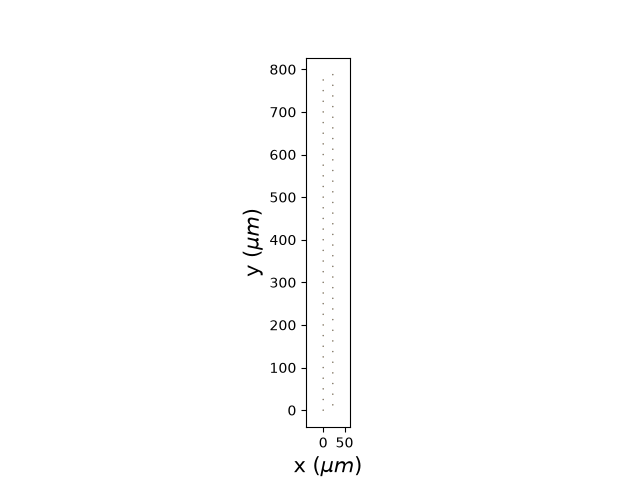

In [13]:
%matplotlib widget
si.plot_probe_map(recording)

In [14]:
probe = recording.get_probe()
probe

Probe - 64ch

The recording is a lazy object that make easy to load tarces into a simple numpy array.

In [15]:
traces = recording.get_traces(segment_index=0, start_frame=100_000, end_frame=200_000)
traces

array([[  285,   192,   325, ...,    -6,    37,  1392],
       [  267,   238,   274, ...,    12,     5,  1453],
       [  261,   148,   226, ...,    -1,    71,  1412],
       ...,
       [  485,   432,   660, ...,   790,  -982,  1151],
       [  538,   560,   596, ...,   801,  -934,  1115],
       [  613,   511,   723, ...,   779, -1001,  1110]],
      shape=(100000, 64), dtype=int16)

The probe layout is essential for the spike sorting algorithms. Hence, it's very important that the probe information is correct.

Your actual raw data is (usually) saved as a binary (or "raw" or "dat") file. This is just a 2D array, with time on one axis and channel index on the other. A good way to think of the probe is that it links the geometric positions of each electrode to the row in your 2D array which contains the raw signal from that channel. If you've done experiments, you know that this "wiring" can depend on lots of intermediate information: how the head stage is wired, a channel selection on your acquisition system etc.

We can plot the raw traces. Note that not all data gets loaded: only the data in the `time_range` is loaded.

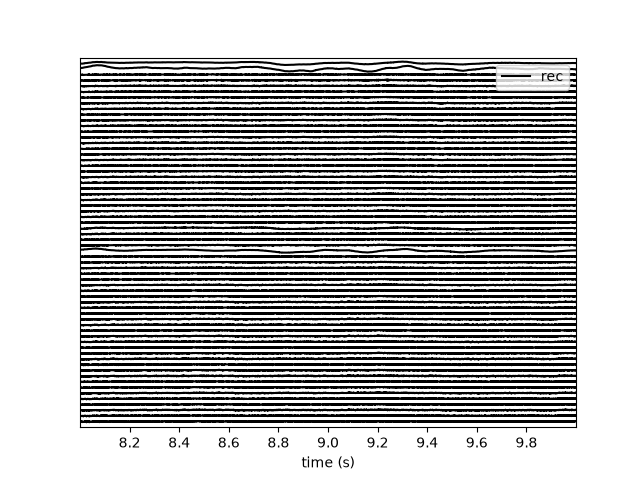

In [16]:
si.plot_traces(
    recording,
    mode="line",  # plot the traces as lines, rather than a heatmap
    time_range = (8,10) # plot all data from 8-10 seconds
)

Hmmm... that doesn't look helpful. We can _slice_ our recording to focus on a small bit of it; either in time or in channels.

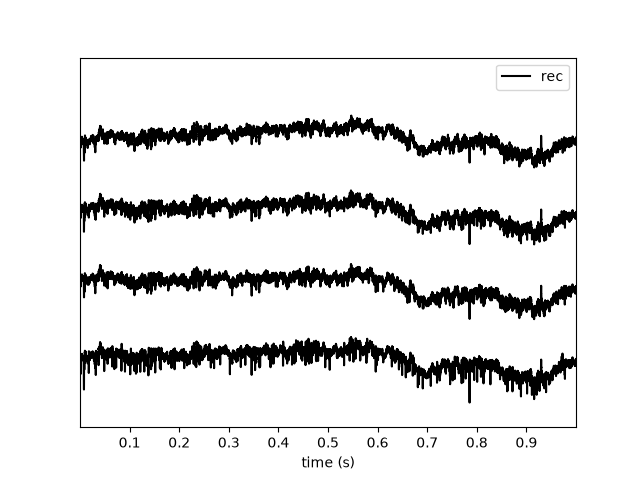

In [17]:
time_sliced_recording = recording.time_slice(start_time=0, end_time=10)
channel_sliced_recording = time_sliced_recording.select_channels(channel_ids=[0,1,2,3])
# Note: you can also remove channels using `recording.remove_channels(...)``

si.plot_traces(channel_sliced_recording)

There are also some interactive plotting tools within SpikeInterface that you can use when in a Jupyter notebook. We need to tell Jupyter to use these tools using a "magic command":

In [18]:
%matplotlib widget
si.plot_traces(recording, backend='ipywidgets')

AppLayout(children=(TimeSlider(children=(Dropdown(description='Segment', options=(0,), value=0), Button(icon='…

There are also other backend for instance QT desktop one.
Be carfull this can make the notebook buggy...

In [19]:
%gui qt
si.plot_traces(recording, backend='ephyviewer')

# Generating your own Probe

The data we've loaded is great: the probe is auto-generated when you load it. This is also generally true for openephys and spikeglx data: you shouldn't have to touch anything to get all of the probe geometry "for free".

But that's not always the case.

Suppose you have a custom probe with 4-shanks, with 8 channels on each shank. We can generate some artificial data to imitate this scenario

In [20]:
fake_recording = si.generate_recording(
    num_channels = 4*8,
    durations = [300],
    set_probe=False,
)

print(fake_recording.has_probe())

False


We can make a probe by creating a `Probe` object from `ProbeInterface`. At a minimum, this needs the locations of each channel. Read more in the ProbeInterface docs: https://probeinterface.readthedocs.io/en/stable/index.html

In [21]:
positions_on_one_shank = np.array([
    [0,0],
    [20,0],
    [0,20],
    [20,20],
    [0,40],
    [20,40],
    [0,60],
    [20,60],
])

all_positions = np.concatenate([
    positions_on_one_shank, 
    positions_on_one_shank+[100,0], 
    positions_on_one_shank+[200,0], 
    positions_on_one_shank+[300,0]
])

In [22]:
from probeinterface import Probe

probe = Probe(ndim=2, si_units='um')
probe.set_contacts(positions=all_positions)

# We need to "wire" the probe, to say which channel corresponds to which column in the raw traces file. 
probe.set_device_channel_indices(range(0,4*8))

# And we'll make an auto-shape in the hope of making prettier plots
probe.create_auto_shape()

fake_recording.set_probe(probe)

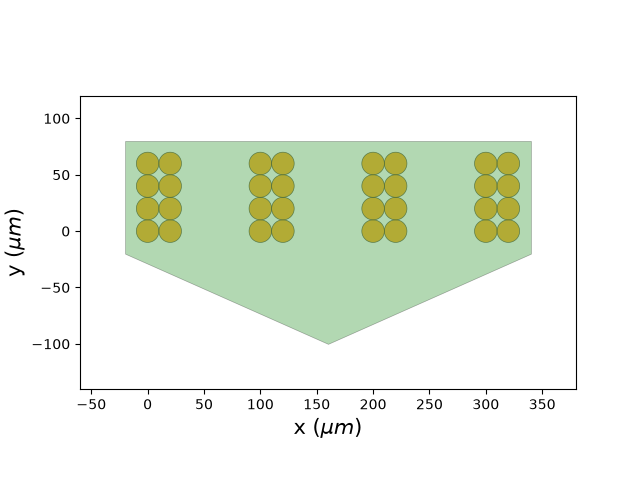

In [23]:
si.plot_probe_map(fake_recording)

These four shanks are far apart from each other, and we might want to deal with them independently. We can set a "group" property to each electrode:

In [24]:
fake_recording.set_channel_groups([0,0,0,0,0,0,0,0,1,1,1,1,1,1,1,1,2,2,2,2,2,2,2,2,3,3,3,3,3,3,3,3])

We can then split the recording using the `split_by` method:

In [25]:
grouped_recordings = fake_recording.split_by('group')
grouped_recordings

{0: SyntheticRecording (ChannelSliceRecording): 8 channels - 30.0kHz - 1 segments - 9,000,000 samples 
                     300.00s (5.00 minutes) - float32 dtype - 274.66 MiB,
 1: SyntheticRecording (ChannelSliceRecording): 8 channels - 30.0kHz - 1 segments - 9,000,000 samples 
                     300.00s (5.00 minutes) - float32 dtype - 274.66 MiB,
 2: SyntheticRecording (ChannelSliceRecording): 8 channels - 30.0kHz - 1 segments - 9,000,000 samples 
                     300.00s (5.00 minutes) - float32 dtype - 274.66 MiB,
 3: SyntheticRecording (ChannelSliceRecording): 8 channels - 30.0kHz - 1 segments - 9,000,000 samples 
                     300.00s (5.00 minutes) - float32 dtype - 274.66 MiB}

Many of `SpikeInterface`'s functions work exactly the same way with a recording, or a group of recordings (like the one above)

`ProbeInterface` also has some helper probe creation functions such as `generate_multi_shank` and `generate_linear`. Read more in the docs: https://probeinterface.readthedocs.io/en/stable/index.html

There is also a library of probes you can load in https://probeinterface.readthedocs.io/en/stable/examples/ex_10_get_probe_from_library.html, mostly from Cambridge Neurotech and NeuroNexus.

`SpikeInterface` also contains some pretty advanced generation tools. We can make fake data that imitates a multi-shank recording like so

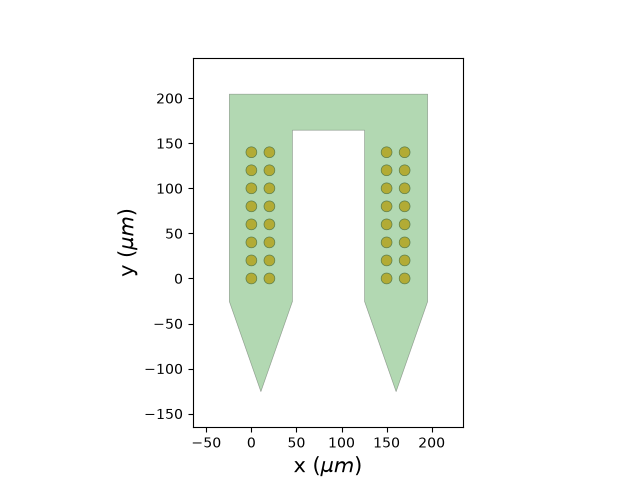

In [26]:
from probeinterface import generate_multi_shank
two_shank_probe = generate_multi_shank(num_shank=2, num_contact_per_column=8, num_columns=2)
two_shank_probe.set_device_channel_indices(range(32))
si_generated_recording, _ = si.generate_ground_truth_recording(
    durations=[300],
    num_channels=32,
    probe=two_shank_probe
)
si.plot_probe_map(si_generated_recording)

You can also download a probe from our libray.

(<matplotlib.collections.PolyCollection at 0x776b0df1f0e0>,
 <matplotlib.collections.PolyCollection at 0x776b0d43cb90>)

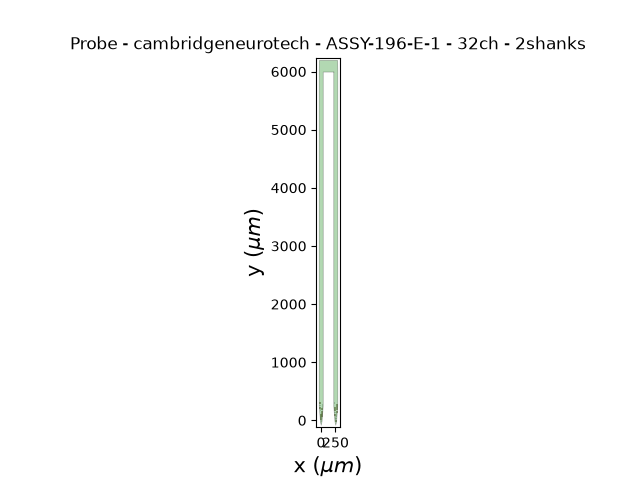

In [27]:
from probeinterface import get_probe
from probeinterface.plotting import plot_probe
probe = get_probe("cambridgeneurotech", "ASSY-196-E-1")
plot_probe(probe)

(<matplotlib.collections.PolyCollection at 0x776b0d177f50>,
 <matplotlib.collections.PolyCollection at 0x776b0d177e00>)

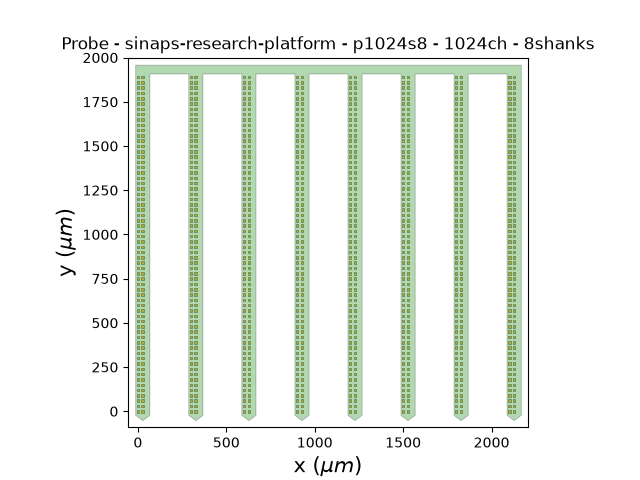

In [28]:
probe = get_probe("sinaps-research-platform", "p1024s8")
plot_probe(probe)

## Save a recording

In [29]:
rec2 = recording.save(folder=result_folder / f"{recording_name}-copy", format="binary")
rec2

write_binary (no parallelization):   0%|          | 0/90 [00:00<?, ?it/s]

BinaryFolderRecording: 64 channels - 20.0kHz - 1 segments - 1,800,000 samples 
                       90.00s (1.50 minutes) - int16 dtype - 219.73 MiB

In [30]:
# with parallelisation!
job_kwargs = {"chunk_duration": "1s", "n_jobs": 8, "progress_bar":True}
si.set_global_job_kwargs(**job_kwargs)

rec2 = recording.save(folder=result_folder / f"{recording_name}-copy2", format="binary")
rec2

write_binary (workers: 8 processes fork):   0%|          | 0/90 [00:00<?, ?it/s]

BinaryFolderRecording: 64 channels - 20.0kHz - 1 segments - 1,800,000 samples 
                       90.00s (1.50 minutes) - int16 dtype - 219.73 MiB

# Save with with compression zarr format

`SpikeInterface` allows you to compress your raw data if you save it in the [Zarr](https://zarr.dev/) format. Read more [here](https://iopscience.iop.org/article/10.1088/1741-2552/acf5a4/meta)!

We just need to adjust our settings when we save the recording

In [31]:
zarr_folder = result_folder / f"{recording_name}-copy-compressed.zarr"
rec4 = recording.save(folder=zarr_folder, format="zarr")

write_zarr (workers: 8 processes fork):   0%|          | 0/90 [00:00<?, ?it/s]

Let's check if this is smaller than our binary recording

In [32]:
def get_folder_size_mb(path="."):
    total_size = 0
    for dirpath, _, filenames in os.walk(path):
        for f in filenames:
            fp = os.path.join(dirpath, f)
            total_size += os.path.getsize(fp)
    return total_size / (1024 ** 2)


size_binary = get_folder_size_mb(path=path_to_recording)
size_zarr = get_folder_size_mb(path=zarr_folder)
print(f"Size of preprocessed binary folder: {size_binary:.2f} MB")
print(f"Size of preprocessed Zarr folder: {size_zarr:.2f} MB")

Size of preprocessed binary folder: 219.86 MB
Size of preprocessed Zarr folder: 144.64 MB


You can use different compression strategies to try and make your file even smaller. Read more in our docs: https://spikeinterface.readthedocs.io/en/stable/modules/core.html#saving-loading-and-compression

Be warned that if you use a codec (like WavPak) to compress your file, whoever opens the file will need to install the codec too.

### Slice in time and or channels

In [33]:
some_chan_ids = recording.channel_ids[::3]
print(some_chan_ids)
some_chans_recording = recording.select_channels(some_chan_ids)
some_chans_recording

[ 0  3  6  9 12 15 18 21 24 27 30 33 36 39 42 45 48 51 54 57 60 63]


ChannelSliceRecording: 22 channels - 20.0kHz - 1 segments - 1,800,000 samples 
                       90.00s (1.50 minutes) - int16 dtype - 75.53 MiB

In [34]:
recording_30s = recording.time_slice(start_time=0, end_time=30)
recording_30s

FrameSliceRecording: 64 channels - 20.0kHz - 1 segments - 600,000 samples - 30.00s - int16 dtype 
                     73.24 MiB

Recording is a rich object that offer many more

In [35]:
recording.get_dtype()

dtype('int16')

In [36]:
recording.get_shape()

(1800000, 64)

In [37]:
recording.get_total_memory_size()

230400000

In [38]:
rec_float32 = recording.astype("float32")
rec_float32

astype (AstypeRecording): 64 channels - 20.0kHz - 1 segments - 1,800,000 samples 
        90.00s (1.50 minutes) - float32 dtype - 439.45 MiB